# Домашнее задание 2. Линейная регрессия и градиентный спуск

## Математические методы анализа данных

В этом задании вы:

- **Обучите линейные модели** для предсказания цены подержанного автомобиля на данных из ДЗ-1: `LinearRegression`, `Lasso`, `ElasticNet`, `Ridge`, подберете гиперпараметры на кросс-валидации, примените one-hot-кодирование категорий;
- **Реализуете градиентный спуск** своими руками, посмотрите, как он ведёт себя на выпуклой и невыпуклой функции, и обучите с помощью него линейную регрессию.

**Дедлайн: 17 октября 2026, 23:59 (МСК).** Работы после дедлайна не принимаются.

**Максимальный балл за задание — 10.**

| Часть | Баллы |
|---|---|
| 0. Подготовка данных | 0 |
| 1. Линейная регрессия | 5 |
| 2. Градиентный спуск | 5 |
| **Итого** | **10** |

## <font color="red">Правила выполнения</font>

- Сдаём файл `.ipynb` через LMS. Перед сдачей перезапустите ноутбук и выполните все ячейки сверху вниз (*Kernel → Restart & Run All*, в Colab — *Среда выполнения → Перезапустить сеанс и выполнить все*). Ноутбук должен отработать без ошибок, все выводы и графики должны сохраниться.
- Если пользуетесь LLM или готовыми решениями из интернета, напишите об этом рядом с кодом: какая модель или какой ресурс. Решение нужно понимать полностью.
- После дедлайна 10–15 % работ случайно выбираются для онлайн-защиты: попросим объяснить решение. Если автор не может объяснить свой код, задание обнуляется.
- Оцениваются и код, и текстовые ответы. Если нет одного из двух, балл за пункт снижается.
- В каждом пункте сказано, на какой выборке работать: train или test. Всё, что «обучается» (scaler, кодировщик, модель), обучаем **только на train**, а к test только применяем.
- Ячейки с `assert` не меняйте: они проверяют, что у вас получились данные нужного размера или верные функции.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go

from sklearn.linear_model import LinearRegression, Lasso, ElasticNet, Ridge
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error

# Часть 0. Подготовка данных (0 баллов)

Работаем с теми же данными, что в ДЗ-1: объявления о продаже подержанных автомобилей в Индии. Целевая переменная (таргет) — `selling_price`, цена в рупиях.

| Признак | Что означает |
|---|---|
| `name` | марка и модель |
| `year` | год выпуска |
| `selling_price` | цена продажи в рупиях — **таргет** |
| `km_driven` | пробег, км |
| `fuel` | тип топлива |
| `seller_type` | кто продаёт: частное лицо или дилер |
| `transmission` | коробка передач |
| `owner` | какой по счёту владелец |
| `mileage` | сколько км машина проезжает на литре топлива (kmpl) или килограмме газа (km/kg) |
| `engine` | объём двигателя, см³ |
| `max_power` | мощность, л. с. (bhp) |
| `seats` | число мест |

Ниже — готовая предобработка по шагам ДЗ-1:
- убираем единицы измерения
- удаляем `torque`
- чиним `km_driven`
- заполняем пропуски медианами по train
- приводим `seats` к `int`
- удаляем дубли.

**Просто запустите ячейку.** Даже если в ДЗ-1 вы делали иначе, используйте этот код: тогда у всех одинаковые данные и ответы можно сверять.

In [2]:
URL = 'https://raw.githubusercontent.com/paiflare/ml_hse_2026/refs/heads/master/homework/hw_1/Data/'
df_train = pd.read_csv(URL + 'new_cars_train.csv')
df_test = pd.read_csv(URL + 'new_cars_test.csv')

for df in [df_train, df_test]:
    # '23.4 kmpl' -> 23.4, '1248 CC' -> 1248, '74 bhp' -> 74; если числа нет -> NaN
    for col in ['mileage', 'engine', 'max_power']:
        df[col] = pd.to_numeric(df[col].str.split().str[0], errors='coerce')
    # torque удаляем, как в ДЗ-1
    df.drop(columns='torque', inplace=True)
    # в km_driven встречаются '-' и пропуски -> NaN
    df['km_driven'] = pd.to_numeric(df['km_driven'], errors='coerce')

# пропуски заполняем медианами, посчитанными только по train
cols_with_na = ['km_driven', 'mileage', 'engine', 'max_power', 'seats']
train_medians = df_train[cols_with_na].median()
df_train[cols_with_na] = df_train[cols_with_na].fillna(train_medians)
df_test[cols_with_na] = df_test[cols_with_na].fillna(train_medians)

df_train['seats'] = df_train['seats'].astype(int)
df_test['seats'] = df_test['seats'].astype(int)

# дубли по признакам (без таргета) удаляем только в train, оставляем первую строку
feature_cols = [col for col in df_train.columns if col != 'selling_price']
df_train = df_train.drop_duplicates(subset=feature_cols, keep='first').reset_index(drop=True)

print('train:', df_train.shape, ' test:', df_test.shape)

train: (5843, 12)  test: (1000, 12)


In [3]:
assert df_train.shape == (5843, 12) and df_test.shape == (1000, 12)
assert df_train.isna().sum().sum() == 0 and df_test.isna().sum().sum() == 0

df_train.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500.0,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000.0,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5
2,Hyundai i20 Sportz Diesel,2010,225000,127000.0,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5
3,Maruti Swift VXI BSIII,2007,130000,120000.0,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5
4,Hyundai Xcent 1.2 VTVT E Plus,2017,440000,45000.0,Petrol,Individual,Manual,First Owner,20.14,1197.0,81.86,5


# Часть 1. Линейная регрессия (5 баллов)

Качество моделей оцениваем двумя метриками:

- **MSE** (среднеквадратичная ошибка, mean squared error): $$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat y_i)^2.$$ Чем меньше, тем лучше. Измеряется в «рупиях в квадрате».
- **$R^2$** (коэффициент детерминации): $$R^2 = 1 - \dfrac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2},$$ где $\bar y$ — среднее таргета **на той же выборке**, на которой считаем метрику. Показывает, какую долю разброса цен объясняет модель; $R^2 = 1$ — идеальные прогнозы.

**Здесь и далее для каждой обученной модели выводите $R^2$ и MSE на train и на test**, даже если в пункте об этом не сказано: иначе непонятно, стало ли лучше.

### Задание 1.1. Числовые признаки (0.25 балла)

Начнём с модели только на числовых признаках: `year`, `km_driven`, `mileage`, `engine`, `max_power`, `seats`.

Запишите в `X_train` и `X_test` эти столбцы из `df_train` и `df_test`, а в `y_train` и `y_test` — таргет `selling_price` из тех же таблиц.

In [4]:
num_features = ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']

X_train = df_train[num_features]
y_train = df_train['selling_price']
X_test = df_test[num_features]
y_test = df_test['selling_price']

In [5]:
assert X_train.shape == (5843, 6) and X_test.shape == (1000, 6)
assert y_train.shape == (5843,) and y_test.shape == (1000,)

### Задание 1.2. Первая модель (0.5 балла)

1. **(0.15)** Напишите функцию `print_metrics(model, X_train, y_train, X_test, y_test)`: она получает уже обученную модель и печатает $R^2$ и MSE на train и на test. Дальше пользуйтесь ей для всех моделей.
2. **(0.15)** Обучите линейную регрессию `LinearRegression` с параметрами по умолчанию на train. Выведите метрики.
3. **(0.2)** Ответьте на вопросы:
   - Какую долю разброса цен на test объясняет модель?
   - Сравните train и test по $R^2$ и по MSE. Почему выводы по двум метрикам расходятся? Подсказка: сравните разброс цен `y_train.std()` и `y_test.std()`.
   - Посчитайте $\text{RMSE} = \sqrt{\text{MSE}}$ на test. Какова типичная ошибка прогноза в рупиях? Много это или мало по сравнению с медианной ценой на train?

In [6]:
def print_metrics(model, X_train, y_train, X_test, y_test):
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)
    print(f"Train R2: {r2_score(y_train, y_pred_train):.4f}, MSE: {mean_squared_error(y_train, y_pred_train):.4f}")
    print(f"Test  R2: {r2_score(y_test, y_pred_test):.4f}, MSE: {mean_squared_error(y_test, y_pred_test):.4f}")

In [7]:
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
print_metrics(lin_reg, X_train, y_train, X_test, y_test)

Train R2: 0.5921, MSE: 116851699646.5966
Test  R2: 0.5940, MSE: 233395049519.1034


In [8]:
from sklearn.metrics import root_mean_squared_error
rmse = root_mean_squared_error(y_test, lin_reg.predict(X_test))
med = y_train.median()
print(f"RMSE = {rmse}, median = {med}, RMSE { ">" if med > rmse else "<" } median")
print(f"train std = {y_train.std()}, test std = {y_test.std()} \ntrain/test = {y_train.std() / y_test.std()}")
print(f"train mse / test mse = {mean_squared_error(y_train, lin_reg.predict(X_train)) / mean_squared_error(y_test, lin_reg.predict(X_test))}")

RMSE = 483109.7696374018, median = 408000.0, RMSE < median
train std = 535300.4778164653, test std = 758553.8607099972 
train/test = 0.7056855228650877
train mse / test mse = 0.5006605747952346


**Ваш ответ:**

*   объясненная доля разброса на test = R2 => 60%
*   в R2 на test и train разницы почти нет => на test разброс не сильно больше train, что хорошо. у mse в train and test достаточно большая разница, но их соотношение ~ mse, а r2 в них примерно равны, то разница в mse объясняется большим разбросом цен в test чем в train
*   RMSE = 483110, что больше, чем median = 408000. Что значит, что ошибка слишком велика

(ai was used for understanding wth is R2)

### Задание 1.3. Может ли $R^2$ быть отрицательным? (0.25 балла)

Часто говорят, что $R^2$ лежит от 0 до 1. Для линейной регрессии это верно **на обучающей выборке**: там модель не хуже константы, равной среднему. На новых данных $R^2$ бывает и меньше нуля. Проверим.

1. **(0.1)** Сделайте «константную модель»: каждому объекту test предскажите одно и то же число — среднюю цену на train `y_train.mean()`. Посчитайте $R^2$ этой модели на test.
2. **(0.15)** Ответьте: почему получилось меньше нуля? Посмотрите на формулу $R^2$: с каким прогнозом на test сравнивается модель? Что в итоге означает $R^2 < 0$?

In [9]:
const_pred = np.full_like(y_test, y_train.mean(), dtype=float)
r2_const = r2_score(y_test, const_pred)
print(f"R2 on const test: {r2_const:.4f}")

R2 on const test: -0.0157


**Ваш ответ:**

так как мы по сути поставили в знаменатель разброс от test, а чмслитель среднее от тренировочной. то есть r2 < 0 значит, что модель на которую мы смотррим хуже чем прогноз на выборке.

### Задание 1.4. Стандартизация и важность признаков (0.5 балла)

1. **(0.1)** Стандартизируйте признаки с помощью `StandardScaler`: обучите его (`fit`) **только на train**, затем преобразуйте (`transform`) и train, и test. Результаты запишите в `X_train_scaled` и `X_test_scaled`.
2. **(0.2)** Обучите `LinearRegression` на `X_train_scaled` и выведите метрики. Изменились ли они по сравнению с 1.2? Объясните почему.
3. **(0.2)** Выведите коэффициенты модели вместе с названиями признаков. Какой признак сильнее всего влияет на цену (по модулю коэффициента)? Почему сравнивать коэффициенты так можно только после стандартизации? Подсказка: сравните коэффициент при `km_driven` в моделях из 1.2 и 1.4.

In [10]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [11]:
lin_reg_scaled = LinearRegression()
lin_reg_scaled.fit(X_train_scaled, y_train)
print_metrics(lin_reg_scaled, X_train_scaled, y_train, X_test_scaled, y_test)

Train R2: 0.5921, MSE: 116851699646.5961
Test  R2: 0.5940, MSE: 233395049519.0977


In [12]:
for name, coef in zip(num_features, lin_reg_scaled.coef_):
    print(f"{name:12s} {coef: .2f}")


year          152898.50
km_driven    -43953.85
mileage       28791.82
engine        61371.07
max_power     322550.14
seats        -23441.05


In [13]:
# # for name, coef in zip(num_features, lin_reg.coef_):
# #     print(f"{name:12s} {coef: .2f}")

**Ваш ответ:**

2. R2 не изменились, mse - на на тысячные доли, то есть тоже не => не изменились (прогнозы не поменялись) т к мы не меняем качество модели
3. сильнее всего влияет на цену max_power. важно делать это после стандартилизации тк все значения изменяются в разном диапазоне, масштабе и единицах измерения. таким образом важно привести их к одному интервалу. так например до стандартилизации km_driven было ~ 0, что не соответствует реальности, так как этот параметр сильно влияет на цену

### Задание 1.5. Lasso (0.25 балла)

Lasso — линейная регрессия с L1-регуляризацией. В sklearn она минимизирует $\frac{1}{2n}\|y - Xw\|^2 + \alpha \sum_j |w_j|$. Из-за штрафа часть весов может стать ровно нулём: модель сама отбирает признаки.

1. **(0.1)** Обучите `Lasso` с параметрами по умолчанию на `X_train_scaled`. Выведите метрики и коэффициенты.
2. **(0.15)** Занулились ли какие-нибудь веса? Предположите почему. Подсказка: по умолчанию `alpha=1`; сравните это число с масштабом коэффициентов из 1.4.

In [14]:
lasso = Lasso()
lasso.fit(X_train_scaled, y_train)
print_metrics(lasso, X_train_scaled, y_train, X_test_scaled, y_test)
print("lasso coefs:")
for name, coef in zip(num_features, lasso.coef_):
    print(f"{name:12s} {coef: .2f}")
print("num of zero:", np.sum(lasso.coef_ == 0))

Train R2: 0.5921, MSE: 116851699656.7038
Test  R2: 0.5940, MSE: 233395718994.1630
lasso coefs:
year          152898.32
km_driven    -43952.72
mileage       28789.94
engine        61366.25
max_power     322551.02
seats        -23438.18
num of zero: 0


**Ваш ответ:**

Никакие веса не обнулились. так как альфа сильно меньше в масштабе чем коэффициенты, то есть пости не влияет

### Задание 1.6. Подбор `alpha` для Lasso по сетке (0.5 балла)

Гиперпараметр `alpha` нельзя подбирать по test: тогда test перестанет быть «новыми данными». Подбираем его на кросс-валидации (cross-validation) внутри train.

1. **(0.2)** С помощью [`GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) подберите `alpha` для `Lasso` на `X_train_scaled`: 5 фолдов (`cv=5`), метрика $R^2$ (`scoring='r2'`), сетка для `alpha` — `np.logspace(1, 5, 9)` (9 значений от 10 до 100 000).
2. **(0.15)** Ответьте:
   - Сколько моделей обучил `GridSearchCV`? Учтите, что после перебора лучшая модель ещё раз обучается на всём train (параметр `refit=True` по умолчанию).
   - Какой `alpha` оказался лучшим? Какие веса занулились при нём?
3. **(0.15)** Выведите метрики лучшей модели (`best_estimator_`) на train и test. Стала ли она лучше `LinearRegression` из 1.4? Почему регуляризация здесь почти не помогает? Подсказка: вспомните, от чего защищает регуляризация, и сравните $R^2$ на train и test в 1.2.

In [15]:
param_grid_lasso = {'alpha': np.logspace(1, 5, 9)}
grid_lasso = GridSearchCV(Lasso(max_iter=100000), param_grid_lasso, cv=5, scoring='r2')
grid_lasso.fit(X_train_scaled, y_train)

best_lasso = grid_lasso.best_estimator_
print("best alpha:", grid_lasso.best_params_)
print("zeros:", np.sum(best_lasso.coef_ == 0))
print_metrics(best_lasso, X_train_scaled, y_train, X_test_scaled, y_test)

best alpha: {'alpha': np.float64(10000.0)}
zeros: 1
Train R2: 0.5891, MSE: 117719059815.0397
Test  R2: 0.5814, MSE: 240615768163.7096


In [16]:
for name, coef in zip(num_features, best_lasso.coef_):
    print(f"{name:12s} {coef: .2f}")

year          151900.85
km_driven    -32542.49
mileage       9300.59
engine        17881.08
max_power     329047.29
seats        -0.00


**Ваш ответ:**

2. 1 - всего 9 * 5 + 1(train) = 46 моделей;  2 - лучший альфа = 10000, занулился 1 коэфициент - seats
3. регуляризация не помогает, потому что переобучения нет, R2 на train ~ R2 на test

### Задание 1.7. ElasticNet (0.25 балла)

[`ElasticNet`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html) совмещает L1- и L2-регуляризацию. В sklearn он минимизирует
$$\frac{1}{2n}\|y - Xw\|^2 + \alpha\,\rho\,\|w\|_1 + \frac{\alpha\,(1 - \rho)}{2}\,\|w\|_2^2,$$
где $\rho$ — параметр `l1_ratio`: при $\rho = 1$ получается Lasso, при $\rho = 0$ — только L2-штраф, как в Ridge.

1. **(0.15)** Подберите `alpha` и `l1_ratio` для `ElasticNet` с помощью `GridSearchCV` на `X_train_scaled`: `cv=5`, `scoring='r2'`, сетка для `alpha` — `np.logspace(-3, 2, 6)`, для `l1_ratio` — `[0.1, 0.3, 0.5, 0.7, 0.9]`.
2. **(0.1)** Ответьте: сколько моделей обучил `GridSearchCV`? Какие гиперпараметры у лучшей модели? Выведите её метрики на train и test.

In [17]:
param_grid_enet = {'alpha': np.logspace(-3, 2, 6), 'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]}
grid_enet = GridSearchCV(ElasticNet(max_iter=100000), param_grid_enet, cv=5, scoring='r2')
grid_enet.fit(X_train_scaled, y_train)

best_enet = grid_enet.best_estimator_
print(f"best params: alpha: {grid_enet.best_params_['alpha']}, l1_ratio: {grid_enet.best_params_['l1_ratio']}")
print_metrics(best_enet, X_train_scaled, y_train, X_test_scaled, y_test)

best params: alpha: 0.1, l1_ratio: 0.5
Train R2: 0.5910, MSE: 117178726919.3600
Test  R2: 0.5830, MSE: 239723536113.3958


**Ваш ответ:**

моделей обучено 6 * 5 * 5 + 1 = 151.

### Задание 1.8. Добавляем категориальные признаки (0.75 балла)

Дадим модели больше информации — категориальные признаки `fuel`, `seller_type`, `transmission`, `owner`. Признак `seats` тоже закодируем как категорию: разных значений у него мало, и нет причин считать, что каждое следующее место меняет цену на одну и ту же сумму. Столбец `name` пока не используем: в нём слишком много уникальных значений (обработаем его в задании 1.11).

1. **(0.25)** Закодируйте `fuel`, `seller_type`, `transmission`, `owner`, `seats` методом one-hot (OHE): `OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)`. Обучите кодировщик на train, примените к train и test. Параметр `handle_unknown='ignore'` нужен на случай, если в test встретится категория, которой не было в train: она закодируется нулями вместо ошибки.
2. **(0.25)** Соберите итоговые матрицы признаков `X_train_all` и `X_test_all`: стандартизированные числовые признаки `year`, `km_driven`, `mileage`, `engine`, `max_power` (новый `StandardScaler`, обученный на train) + OHE-столбцы. Склеить матрицы по столбцам можно через `np.hstack([A, B])`.
3. **(0.25)** Ответьте: зачем `drop='first'`? Что без него случилось бы с матрицей признаков линейной регрессии? Подсказка: dummy trap, «ловушка фиктивных переменных».

In [18]:
cat_features = ['fuel', 'seller_type', 'transmission', 'owner', 'seats']
num_features_2 = ['year', 'km_driven', 'mileage', 'engine', 'max_power']

ohe = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)
ohe.fit(df_train[cat_features])

cat_train = ohe.transform(df_train[cat_features])
cat_test = ohe.transform(df_test[cat_features])

In [19]:
scaler2 = StandardScaler()
num_train = scaler2.fit_transform(df_train[num_features_2])
num_test = scaler2.transform(df_test[num_features_2])

X_train_all = np.hstack([num_train, cat_train])
X_test_all = np.hstack([num_test, cat_test])

In [20]:
assert X_train_all.shape == (5843, 23) and X_test_all.shape == (1000, 23)

**Ваш ответ:**

он убирает одну категорию из каждой группы, чтобы не возникало линейной зависимости между OHE-столбцами и конст столбцом. без этого матрица признаков вырождается и коэффициенты неоднозначны

### Задание 1.9. Ridge на всех признаках (0.5 балла)

1. **(0.25)** Подберите `alpha` для гребневой регрессии `Ridge` (L2-регуляризация) с помощью `GridSearchCV` на `X_train_all`: `cv=5`, `scoring='r2'`, сетка для `alpha` — `np.logspace(-2, 3, 11)`.
2. **(0.25)** Какой `alpha` лучший? Выведите метрики лучшей модели на train и test. Удалось ли улучшить качество по сравнению с моделями только на числовых признаках (1.2–1.7)?

In [21]:
param_grid_ridge = {'alpha': np.logspace(-2, 3, 11)}
grid_ridge = GridSearchCV(Ridge(), param_grid_ridge, cv=5, scoring='r2')
grid_ridge.fit(X_train_all, y_train)

best_ridge = grid_ridge.best_estimator_
print("best alpha:", grid_ridge.best_params_['alpha'])
print_metrics(best_ridge, X_train_all, y_train, X_test_all, y_test)

best alpha: 3.1622776601683795
Train R2: 0.6621, MSE: 96821657497.1884
Test  R2: 0.6405, MSE: 206651380789.8480


**Ваш ответ:**

Да, качество улучшилось (R2 стало больше, Mse - меньше)

### Задание 1.10. Бизнес-метрика (0.5 балла)

Заказчику непонятны $R^2$ и MSE. Он предлагает свою метрику — **долю «хороших» прогнозов**: прогноз хороший, если отличается от реальной цены не больше чем на 15 % в любую сторону, то есть $|\hat y_i - y_i| \le 0.15 \cdot y_i$.

1. **(0.2)** Реализуйте функцию `business_metric(y_true, y_pred)`, которая возвращает эту долю (число от 0 до 1).
2. **(0.2)** Посчитайте её **на test** для моделей из 1.2, 1.6, 1.7 и 1.9 и сведите в таблицу вместе с $R^2$ на test. Какая модель лучше с точки зрения заказчика? Совпадает ли она с лучшей по $R^2$?
3. **(0.1)** Сколько прогнозов на test получились отрицательными у каждой модели? Что это говорит о линейной модели для цен?

In [22]:
def business_metric(y_true, y_pred):
  return np.mean(np.abs(y_pred - y_true) <= 0.15 * y_true)


In [23]:
models = {
    'linReg': lin_reg,
    'lasso': best_lasso,
    'ElasticNet': best_enet,
    'ridge': best_ridge}

X_tests = {
    'linReg': X_test,
    'lasso': X_test_scaled,
    'ElasticNet': X_test_scaled,
    'ridge': X_test_all}

rows = []
for name, model in models.items():
    X_te = X_tests[name]
    y_pred = model.predict(X_te)
    rows.append({
        'model': name,
        'R2': r2_score(y_test, y_pred),
        'business_metric': business_metric(y_test, y_pred),
        'num of < 0': np.sum(y_pred < 0)})

pd.DataFrame(rows)

,model,R2,business_metric,num of < 0
0,linReg,0.593975,0.335,71
1,lasso,0.581413,0.348,68
2,ElasticNet,0.582965,0.340,66
3,ridge,0.640499,0.328,63


**Ваш ответ:**

2. с точки зрения заказчика лучше lasso, так как больше всего "хороших" прогнозов. но лучшая по R2 модель - это ridge. то есть заказчик предпочел модель что хуже предсказывает разброс
3. получилось много отрицательных прогнозов на train, поскольку линейная модель не ограничена снизу и при совокупности признаков снижающих сумму уходит в < 0

### Задание 1.11. Марка из `name` (0.25 балла)

Вместо того чтобы выбрасывать `name`, достаньте из него марку автомобиля — первое слово: `'Maruti Swift Dzire VDI'` → `'Maruti'`. Добавьте марку к категориальным признакам, закодируйте их OHE, как в 1.8, и повторите подбор `Ridge` из 1.9 (та же сетка, `cv=5`). Как изменились $R^2$ и бизнес-метрика на test? Зачем здесь понадобился `handle_unknown='ignore'`?

In [24]:
df_train_brand = df_train.copy()
df_test_brand = df_test.copy()
df_train_brand['brand'] = df_train_brand['name'].str.split().str[0]
df_test_brand['brand'] = df_test_brand['name'].str.split().str[0]

cat_features_brand = cat_features + ['brand']

ohe_brand = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)
ohe_brand.fit(df_train_brand[cat_features_brand])

cat_train_brand = ohe_brand.transform(df_train_brand[cat_features_brand])
cat_test_brand = ohe_brand.transform(df_test_brand[cat_features_brand])

X_train_all_brand = np.hstack([num_train, cat_train_brand])
X_test_all_brand = np.hstack([num_test, cat_test_brand])

grid_ridge_brand = GridSearchCV(Ridge(), param_grid_ridge, cv=5, scoring='r2')
grid_ridge_brand.fit(X_train_all_brand, y_train)
best_ridge_brand = grid_ridge_brand.best_estimator_

print("best alpha:", grid_ridge_brand.best_params_)
print_metrics(best_ridge_brand, X_train_all_brand, y_train, X_test_all_brand, y_test)

y_pred_brand = best_ridge_brand.predict(X_test_all_brand)
print("business metric:", business_metric(y_test, y_pred_brand))
print("num of <0:", np.sum(y_pred_brand < 0))

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


best alpha: {'alpha': np.float64(1.0)}
Train R2: 0.7707, MSE: 65699465702.5031
Test  R2: 0.7807, MSE: 126071338736.9278
business metric: 0.404
num of <0: 56


**Ваш ответ:**

R2 и бизнес метрика выросли, то есть улучшились

handle_unknown='ignore' помогает не падать программе если появляются марки, которых не было в тренировочном сете

### Задание 1.12. Логарифм таргета (0.5 балла)

Цены сильно скошены вправо: много дешёвых машин и немного очень дорогих. Линейной модели часто проще предсказывать не саму цену, а её логарифм.

1. **(0.2)** Подберите `Ridge`, как в 1.9 (на `X_train_all`, та же сетка, `cv=5`), но обучайте на таргете $\log y$ (`np.log(y_train)`).
2. **(0.15)** Прогнозы переведите обратно в рупии через `np.exp` и посчитайте на test $R^2$, MSE, бизнес-метрику и число отрицательных прогнозов.
3. **(0.15)** Сравните с 1.9. Почему логарифм помог? Почему отрицательных прогнозов теперь быть не может?

In [25]:
y_train_log = np.log(y_train)

grid_ridge_log = GridSearchCV(Ridge(), param_grid_ridge, cv=5, scoring='r2')
grid_ridge_log.fit(X_train_all, y_train_log)
best_ridge_log = grid_ridge_log.best_estimator_

y_pred_log = best_ridge_log.predict(X_test_all)
y_pred_exp = np.exp(y_pred_log)

print("best alpha:", grid_ridge_log.best_params_)
print(f"r2: {r2_score(y_test, y_pred_exp):.4f}, MSE: {mean_squared_error(y_test, y_pred_exp):.2f}")
print("business metric:", business_metric(y_test, y_pred_exp))
print("num of negatives:", np.sum(y_pred_exp < 0))

best alpha: {'alpha': np.float64(3.1622776601683795)}
r2: 0.8213, MSE: 102741798310.87
business metric: 0.426
num of negatives: 0


**Ваш ответ:**

помогло, потому что распределение цен скошено. после np.exp прогноз всегда положителен, поэтому отрицательных цен быть не может

# Часть 2. Градиентный спуск (5 баллов)

В машинном обучении мы минимизируем **функцию потерь** $L(w)$, где $w$ — вектор параметров (весов) модели. Например, для линейной регрессии это MSE из части 1.

**Градиентный спуск** (gradient descent, GD) — численный метод минимизации. Градиент $\nabla L(w)$ показывает направление наискорейшего роста функции, поэтому шагаем в обратную сторону:
$$w_{k+1} = w_k - \eta\,\nabla L(w_k),$$
где $w_k$ — параметры на шаге $k$, а $\eta > 0$ — **шаг обучения** (learning rate).

Что нужно решить при реализации:

1. **Инициализация** — из какой точки $w_0$ начинаем.
2. **Шаг обучения $\eta$.** Слишком маленький — спуск идёт очень медленно; слишком большой — «перепрыгивает» минимум и может разойтись. Это главный гиперпараметр спуска, дальше мы изучим его влияние.
3. **Критерий остановки.** Делаем не больше $N$ итераций, но останавливаемся раньше, если норма градиента $\|\nabla L(w_k)\|$ стала меньше порога `tol`: в минимуме гладкой функции градиент равен нулю. Бывают и другие критерии: малое изменение параметров $\|w_{k+1} - w_k\|$ или значения функции $|L(w_{k+1}) - L(w_k)|$.
4. **История обучения.** На каждой итерации сохраняем параметры $w_k$, значение $L(w_k)$ и норму градиента. По ним рисуем траекторию спуска и **кривую обучения** — график значения функции по итерациям.

**Выпуклые и невыпуклые функции.** У выпуклой функции любой локальный минимум — глобальный, поэтому при разумном шаге спуск из любой точки придёт к минимуму. Реальные функции потерь (например, у нейросетей) часто невыпуклые: у них бывают «овраги», плато и локальные минимумы. Посмотрим на спуск по функциям обоих типов.

### Задание 2.1. Функции и их градиенты (0.5 балла)

Реализуйте две функции двух переменных и их градиенты. На вход подаётся `params` — массив NumPy `[x, y]`. Функция возвращает число, градиент — массив `np.array([df/dx, df/dy])`.

1. **Вытянутая квадратичная функция** (выпуклая): $f(x, y) = x^2 + 4y^2$. Минимум — в точке $(0, 0)$.
2. **[Функция Розенброка](https://ru.wikipedia.org/wiki/%D0%A4%D1%83%D0%BD%D0%BA%D1%86%D0%B8%D1%8F_%D0%A0%D0%BE%D0%B7%D0%B5%D0%BD%D0%B1%D1%80%D0%BE%D0%BA%D0%B0)** (Rosenbrock function, невыпуклая): $f(x, y) = (a - x)^2 + b\,(y - x^2)^2$ с параметрами $a$ и $b$ (по умолчанию $a = 1$, $b = 100$). Минимум — в точке $(a, a^2)$, на дне длинного изогнутого «оврага».

Производные посчитайте на бумаге. Следующая ячейка сверит ваши градиенты с численными. Баллы: квадратичная функция — 0.2, функция Розенброка — 0.3.

In [26]:
def quadratic_loss(params):
    """f(x, y) = x^2 + 4y^2"""
    x, y = params
    return x**2 + 4 * y**2


def quadratic_grad(params):
    """Градиент: np.array([df/dx, df/dy])"""
    x, y = params
    return np.array([2 * x, 8 * y])


def rosenbrock_loss(params, a=1, b=100):
    """f(x, y) = (a - x)^2 + b(y - x^2)^2"""
    x, y = params
    return (a - x)**2 + b * (y - x**2)**2


def rosenbrock_grad(params, a=1, b=100):
    """Градиент: np.array([df/dx, df/dy])"""
    x, y = params
    return np.array([-2 * (a - x) - 4*b*x*(y - x**2), 2*b*(y - x**2)])

In [27]:
# Проверка: сравниваем ваши градиенты с численными (центральная разностная производная)
def numerical_grad(f, params, h=1e-6):
    grad = np.zeros(len(params))
    for i in range(len(params)):
        step = np.zeros(len(params))
        step[i] = h
        grad[i] = (f(params + step) - f(params - step)) / (2 * h)
    return grad


test_points = [np.array([1.0, 2.0]), np.array([-1.2, 1.0]), np.array([0.5, -0.3])]
for p in test_points:
    assert np.allclose(quadratic_grad(p), numerical_grad(quadratic_loss, p), rtol=1e-4), f'quadratic_grad, точка {p}'
    assert np.allclose(rosenbrock_grad(p), numerical_grad(rosenbrock_loss, p), rtol=1e-4), f'rosenbrock_grad, точка {p}'
    # lambda — короткая безымянная функция: здесь это Розенброк с a=2, b=10
    assert np.allclose(rosenbrock_grad(p, a=2, b=10),
                       numerical_grad(lambda q: rosenbrock_loss(q, a=2, b=10), p), rtol=1e-4), \
        f'rosenbrock_grad с a=2, b=10, точка {p}'
assert quadratic_loss(np.array([0.0, 0.0])) == 0 and rosenbrock_loss(np.array([1.0, 1.0])) == 0
print('Всё верно: градиенты совпадают с численными.')

Всё верно: градиенты совпадают с численными.


### Задание 2.2. Класс `GradientDescent` (1 балл)

Допишите класс градиентного спуска. Он принимает:

- `learning_rate` — шаг обучения $\eta_0$;
- `n_iterations` — максимальное число итераций;
- `decay` — параметр расписания шага (пригодится в задании 2.5). Если `decay=None`, шаг постоянный: $\eta_k = \eta_0$. Если задано число, шаг уменьшается по правилу **inverse time decay**: $\eta_k = \dfrac{\eta_0}{1 + \text{decay}\cdot k}$, где $k$ — номер итерации (0, 1, 2, …);
- `tol` — порог для критерия остановки: если норма градиента стала меньше `tol`, останавливаемся. Если `tol=None`, делаем все `n_iterations` итераций.

Метод `fit(loss_fn, grad_fn, initial_params)` запускает спуск из точки `initial_params` и возвращает найденные параметры. В словарь `self.history` записываются параметры, значение функции и норма градиента **в каждой посещённой точке, включая стартовую**, а также шаг обучения на каждой итерации. Норму вектора считайте через `np.linalg.norm`.

Баллы: вычисления на итерации и шаг спуска — 0.5; остановка по `tol` — 0.25; расписание шага — 0.25.

In [28]:
class GradientDescent:
    """Градиентный спуск с историей обучения.

    learning_rate : float — базовый шаг обучения eta_0
    n_iterations  : int — максимальное число итераций
    decay         : float или None — параметр inverse time decay (None — шаг постоянный)
    tol           : float или None — останавливаемся, когда норма градиента < tol
    """

    def __init__(self, learning_rate=0.01, n_iterations=100, decay=None, tol=None):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.decay = decay
        self.tol = tol

    def fit(self, loss_fn, grad_fn, initial_params):
        self.history = {'params': [], 'loss': [], 'grad_norm': [], 'lr': []}
        params = np.array(initial_params, dtype=float)

        # n_iterations + 1: точку после последнего шага тоже записываем в историю
        for k in range(self.n_iterations + 1):
            loss = loss_fn(params)       # ваш код здесь: значение функции в текущей точке
            grad = grad_fn(params)       # ваш код здесь: градиент в текущей точке
            grad_norm = np.linalg.norm(grad)  # ваш код здесь: норма градиента

            self.history['params'].append(params.copy())
            self.history['loss'].append(loss)
            self.history['grad_norm'].append(grad_norm)

            # --- критерии остановки ---
            if k == self.n_iterations:  # итерации закончились
                break
            if not np.isfinite(loss):   # спуск разошёлся: значения улетели в бесконечность
                break
            if self.tol is not None and grad_norm < self.tol:
                break

            # --- шаг обучения на итерации k ---
            if self.decay is None:
                lr_k = self.learning_rate
            else:
                lr_k = self.learning_rate / (1 + self.decay * k)
            self.history['lr'].append(lr_k)

            # --- шаг градиентного спуска ---
            params =  params - lr_k * grad

        return params

In [29]:
# Проверка класса на квадратичной функции
gd = GradientDescent(learning_rate=0.1, n_iterations=100, tol=1e-6)
final = gd.fit(quadratic_loss, quadratic_grad, np.array([1.0, 1.0]))
assert np.allclose(final, [0, 0], atol=1e-6), 'спуск не пришёл в минимум (0, 0)'
assert np.allclose(gd.history['params'][0], [1.0, 1.0]), 'в истории нет стартовой точки'
assert gd.history['grad_norm'][-1] < 1e-6 and len(gd.history['loss']) < 101, 'не сработала остановка по tol'

gd_decay = GradientDescent(learning_rate=0.1, n_iterations=3, decay=0.5)
gd_decay.fit(quadratic_loss, quadratic_grad, np.array([1.0, 1.0]))
assert np.allclose(gd_decay.history['lr'], [0.1, 0.1 / 1.5, 0.1 / 2]), 'расписание шага работает неверно'
assert len(gd_decay.history['params']) == 4, 'в истории должны быть старт и 3 шага'
print('Класс работает верно.')

Класс работает верно.


### Функции для графиков (готовые)

Две готовые функции на [plotly](https://plotly.com/python/): графики можно приближать, вращать и наводить на точки. Разбираться в коде не обязательно, достаточно понимать, что функции принимают:

- `plot_gd_2d(loss_fn, history_dict, x_range, y_range, title, min_point)` — линии уровня функции и траектории спуска, вид сверху;
- `plot_gd_3d(...)` с теми же аргументами — поверхность функции и траектории на ней в 3D.

`history_dict` — словарь `{подпись: gd.history}`, например `{'lr=0.1': gd.history}`. `x_range`, `y_range` — сетки значений по осям (`np.linspace`), `min_point` — точка минимума для отметки на графике. Траектории, которые ушли за пределы графика, обрезаются, а очень длинные прореживаются. Щелчок по подписи в легенде прячет траекторию, двойной щелчок оставляет только её — пригодится, когда траектории накладываются друг на друга.

Если вместо графика появилась ошибка про `nbformat`, выполните `%pip install nbformat` и перезапустите ядро.

In [30]:
def _prepare_trajectory(history, x_range, y_range, max_points=3000):
    """Траектория (T, 2): обрезаем на первом выходе за рамку графика и прореживаем длинные."""
    traj = np.array(history['params'], dtype=float)
    inside = (np.isfinite(traj).all(axis=1)
              & (traj[:, 0] >= x_range.min()) & (traj[:, 0] <= x_range.max())
              & (traj[:, 1] >= y_range.min()) & (traj[:, 1] <= y_range.max()))
    left_frame = not inside.all()
    if left_frame:
        traj = traj[:np.argmin(inside)]  # до первой точки за рамкой
    if len(traj) > max_points:  # прореживаем, последнюю точку оставляем обязательно
        step = int(np.ceil(len(traj) / max_points))
        if step % 2 == 0:
            step += 1  # нечётный шаг: колебания «туда-обратно» не пропадут при прореживании
        traj = traj[np.unique(np.r_[np.arange(0, len(traj), step), len(traj) - 1])]
    return traj, left_frame


def _surface(loss_fn, x_range, y_range):
    """Значения функции на сетке: Z[i, j] = f(x_range[j], y_range[i])."""
    return np.array([[loss_fn(np.array([x, y])) for x in x_range] for y in y_range])


def _starts_and_min(history_dict, min_point):
    """Стартовые точки всех траекторий (без повторов) и точка минимума."""
    starts = {tuple(np.round(h['params'][0], 6)) for h in history_dict.values()}
    return sorted(starts), min_point


def plot_gd_2d(loss_fn, history_dict, x_range, y_range, title='', min_point=None):
    """Линии уровня функции + траектории спуска (вид сверху).
    Линии уровня рисуем для log(1 + f): так лучше виден «овраг» функции Розенброка."""
    Z = _surface(loss_fn, x_range, y_range)
    fig = go.Figure(go.Contour(x=x_range, y=y_range, z=np.log1p(Z), colorscale='Viridis',
                               ncontours=30, showscale=False, opacity=0.8, hoverinfo='skip'))
    for label, history in history_dict.items():
        traj, left_frame = _prepare_trajectory(history, x_range, y_range)
        fig.add_trace(go.Scatter(x=traj[:, 0], y=traj[:, 1], mode='lines+markers',
                                 name=label + (' (ушла за рамку)' if left_frame else ''),
                                 marker=dict(size=4), line=dict(width=2)))
    starts, min_point = _starts_and_min(history_dict, min_point)
    fig.add_trace(go.Scatter(x=[s[0] for s in starts], y=[s[1] for s in starts], mode='markers',
                             name='Старт', marker=dict(size=12, symbol='x', color='black')))
    if min_point is not None:
        fig.add_trace(go.Scatter(x=[min_point[0]], y=[min_point[1]], mode='markers', name='Минимум',
                                 marker=dict(size=14, symbol='star', color='red')))
    fig.update_layout(title=title, xaxis_title='x', yaxis_title='y', height=600,
                      xaxis=dict(range=[x_range.min(), x_range.max()], constrain='domain'),
                      yaxis=dict(range=[y_range.min(), y_range.max()], constrain='domain',
                                 scaleanchor='x', scaleratio=1))  # одинаковый масштаб осей
    fig.show()


def plot_gd_3d(loss_fn, history_dict, x_range, y_range, title='', min_point=None):
    """Поверхность функции + траектории спуска в 3D."""
    Z = _surface(loss_fn, x_range, y_range)
    fig = go.Figure(go.Surface(x=x_range, y=y_range, z=Z, colorscale='Viridis',
                               opacity=0.7, showscale=False))
    for label, history in history_dict.items():
        traj, left_frame = _prepare_trajectory(history, x_range, y_range)
        z = [loss_fn(p) for p in traj]
        fig.add_trace(go.Scatter3d(x=traj[:, 0], y=traj[:, 1], z=z, mode='lines+markers',
                                   name=label + (' (ушла за рамку)' if left_frame else ''),
                                   marker=dict(size=3), line=dict(width=4)))
    if min_point is not None:
        z_min = loss_fn(np.array(min_point, dtype=float))
        fig.add_trace(go.Scatter3d(x=[min_point[0]], y=[min_point[1]], z=[z_min], mode='markers',
                                   name='Минимум', marker=dict(size=6, symbol='diamond', color='red')))
    fig.update_layout(title=title, height=700,
                      scene=dict(xaxis_title='x', yaxis_title='y', zaxis_title='f(x, y)'))
    fig.show()

### Задание 2.3. Шаг обучения на квадратичной функции (0.75 балла)

Изучим, как шаг $\eta$ влияет на спуск по функции $f(x, y) = x^2 + 4y^2$.

1. **(0.2)** Для каждого шага из списка `learning_rates` запустите `GradientDescent` из точки `(-1.8, 1.2)` с `n_iterations=100` и `tol=1e-3`. Историю каждого запуска сохраните в словарь `results_quadratic` с ключом `f'lr={lr}'`. Для каждого шага выведите, сколько итераций сделано (это `len(history['loss']) - 1`), финальное значение функции и финальную точку.
2. Запустите готовую ячейку с графиками траекторий.
3. **(0.15)** Постройте кривые обучения: значение функции по итерациям для всех шагов на одном графике. По оси $y$ — логарифмическая шкала (`plt.yscale('log')`). Подпишите оси, добавьте легенду. Расходящийся запуск растянет ось на десятки порядков — ограничьте её, например `plt.ylim(1e-9, 1e3)`, чтобы остальные кривые было хорошо видно.
4. **(0.4)** Ответьте на вопросы:
   - При каких $\eta$ спуск остановился по критерию `tol` и за сколько итераций? Почему при $\eta = 0.01$ он не успел?
   - При $\eta = 0.2$ траектория идёт зигзагом. Почему зигзаг по оси $y$, а по оси $x$ его нет?
   - При $\eta = 0.25$ значение функции перестаёт меняться. Это сходимость? Посмотрите на траекторию и на `history['grad_norm']`.
   - Что происходит при $\eta = 0.3$?
   - Объясните всё это формулой. Один шаг спуска по каждой координате: $x_{k+1} = x_k - \eta \cdot 2x_k = (1 - 2\eta)\,x_k$ и $y_{k+1} = (1 - 8\eta)\,y_k$. При каких $\eta$ координата $y$ стремится к нулю? А $x$? Почему допустимый шаг ограничен самым «крутым» направлением, а скорость сходимости — самым пологим?

In [31]:
learning_rates = [0.01, 0.1, 0.2, 0.25, 0.3]
start_quadratic = np.array([-1.8, 1.2])
results_quadratic = {}

# ваш код здесь
for lr in learning_rates:
    gd = GradientDescent(learning_rate=lr, n_iterations=100, tol=1e-3)
    final = gd.fit(quadratic_loss, quadratic_grad, start_quadratic)
    results_quadratic[f'lr={lr}'] = gd.history
    print(f"lr={lr}: iters={len(gd.history['loss']) - 1}, fin={gd.history['loss'][-1]}, point={final}")

lr=0.01: iters=100, fin=0.05698527660310668, point=[-0.2387152   0.00028705]
lr=0.1: iters=37, fin=2.1837556800392014e-07, point=[-4.67306717e-04  1.64926744e-26]
lr=0.2: iters=19, fin=3.3418736347109375e-08, point=[-1.09684753e-04 -7.31231688e-05]
lr=0.25: iters=100, fin=5.76, point=[-1.41994963e-30  1.20000000e+00]
lr=0.3: iters=100, fin=9.683438954802201e+29, point=[-2.89248848e-40  4.92022331e+14]


In [32]:
x_range = np.linspace(-2, 2, 100)
y_range = np.linspace(-2, 2, 100)

plot_gd_2d(quadratic_loss, results_quadratic, x_range, y_range,
           title='f(x, y) = x² + 4y²: траектории спуска', min_point=(0, 0))
plot_gd_3d(quadratic_loss, results_quadratic, x_range, y_range,
           title='f(x, y) = x² + 4y²: траектории спуска (3D)', min_point=(0, 0))

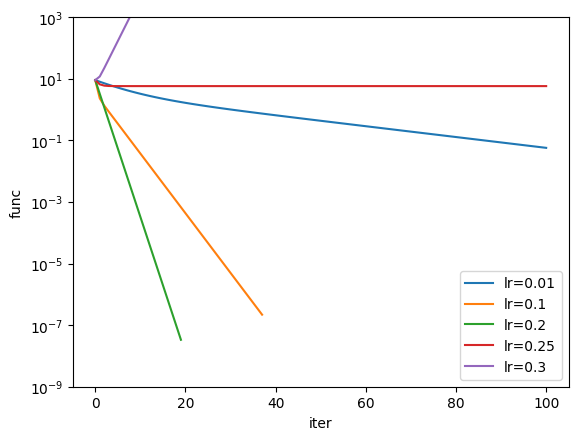

In [33]:
for label, hist in results_quadratic.items():
    plt.plot(hist['loss'], label=label)
plt.yscale('log')
plt.ylim(1e-9, 1e3)
plt.xlabel('iter')
plt.ylabel('func')
plt.legend()
plt.show()

**Ваш ответ:**
* по tol останавливился r=0.3. при 0.01 шаг слишком мал, за 100 итераций не успевает.
* при lr=0.2 координата y меняет знак, поэтому траектория зигзагом по y, по x множитель > 0 =Ю знак не меняется
* при lr=0.25 значение функции не меняется т к y колеблется с одинаковой амплитудой = -1, градиент не стремится к нулю
* при lr=0.3 коэф > 1, спуск расходится
* для y нужно < 1, то есть 0 < н < 0.25. Для x — 0< н < 1. Ограничение задаёт самое крутое направление у, а скорость сходимости — самое пологое х

### Задание 2.4. Шаг обучения на функции Розенброка (0.5 балла)

Теперь невыпуклая функция Розенброка ($a = 1$, $b = 100$, минимум в точке $(1, 1)$).

1. **(0.15)** Для каждого шага из `learning_rates_rosen` запустите спуск из точки `(-1.5, 2.0)` с `n_iterations=10000` и `tol=1e-3`. Истории сохраните в словарь `results_rosen`, выведите число итераций, финальное значение функции и финальную точку. Если увидите предупреждение `RuntimeWarning: overflow` — это не ошибка в коде, а признак того, что спуск разошёлся.
2. Запустите готовую ячейку с графиками.
3. **(0.1)** Постройте кривые обучения для всех шагов (логарифмическая шкала по $y$). Расходящийся запуск улетает к огромным значениям и растягивает ось — ограничьте её, например `plt.ylim(1e-7, 1e4)`, чтобы остальные кривые было видно.
4. **(0.25)** Ответьте на вопросы:
   - При каком $\eta$ спуск остановился по `tol` около минимума? Сколько итераций понадобилось?
   - Как выглядит траектория: как спуск ведёт себя в начале и как — на дне «оврага»? Почему по дну оврага он движется так медленно?
   - Что произошло при $\eta = 0.0025$?
   - В задании 2.3 хорошо работал шаг 0.1. Почему здесь нельзя взять такой же? Подсказка: сравните норму градиента двух функций в стартовых точках (первое значение в `history['grad_norm']`).

In [34]:
learning_rates_rosen = [0.0001, 0.0005, 0.001, 0.0018, 0.0025]
start_rosen = np.array([-1.5, 2.0])
results_rosen = {}

for lr in learning_rates_rosen:
    gd = GradientDescent(learning_rate=lr, n_iterations=10000, tol=1e-3)
    final = gd.fit(rosenbrock_loss, rosenbrock_grad, start_rosen)
    results_rosen[f'lr={lr}'] = gd.history
    print(f"lr={lr}: iters={len(gd.history['loss']) - 1}, fin={gd.history['loss'][-1]}, point={final}")


lr=0.0001: iters=10000, fin=2.7817561589716813, point=[-0.66593918  0.45147674]
lr=0.0005: iters=10000, fin=0.006545252794798543, point=[0.91916852 0.84453129]
lr=0.001: iters=10000, fin=9.6155863643521e-05, point=[0.99020202 0.98046061]
lr=0.0018: iters=8229, fin=1.249133346669188e-06, point=[0.99888325 0.99776327]
lr=0.0025: iters=8, fin=inf, point=[-2.25815965e+119  1.85412823e+079]


/tmp/ipykernel_1504/2950296217.py:16: RuntimeWarning:

overflow encountered in scalar power

/tmp/ipykernel_1504/2950296217.py:22: RuntimeWarning:

overflow encountered in scalar multiply



In [35]:
x_range = np.linspace(-2, 2, 150)
y_range = np.linspace(-1, 3, 150)

plot_gd_2d(rosenbrock_loss, results_rosen, x_range, y_range,
           title='Функция Розенброка: траектории спуска', min_point=(1, 1))
plot_gd_3d(rosenbrock_loss, results_rosen, x_range, y_range,
           title='Функция Розенброка: траектории спуска (3D)', min_point=(1, 1))

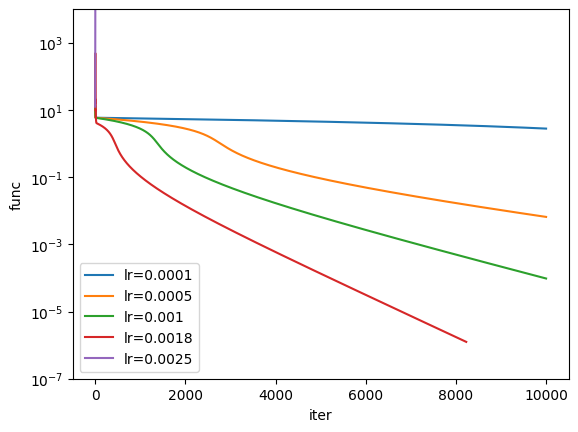

In [36]:
for label, hist in results_rosen.items():
    plt.plot(hist['loss'], label=label)
plt.yscale('log')
plt.ylim(1e-7, 1e4)
plt.xlabel('iter')
plt.ylabel('func')
plt.legend()
plt.show()

**Ваш ответ:**
* около минимума по tol останавливается lr=0.0018
* в начале спуск быстро скатывается по крутым склонам, затем медленно движется по дну оврага, где градиент мал
* при lr=0.0025 спуск расходится
* шаг 0.1 из 2.3 здесь не подходит, потому что градиент розенбокка в стартовой точке намного больше, норма градиента в (-1.5, 2.0) - сотни, а у квадратичной функции - десятки

### Задание 2.5. Расписание шага (0.75 балла)

Мы видели дилемму: большой шаг быстро двигает спуск вперёд, но не даёт «успокоиться» у минимума и может разойтись; маленький шаг устойчив, но медленный. Отсюда идея — **менять шаг по ходу обучения** (learning rate schedule): в начале шагать крупно, потом всё мельче: $\eta_k = \eta(k)$.

Популярные расписания:

- **step decay** — уменьшать шаг в $\gamma$ раз каждые несколько итераций: $\eta_k = \eta_0 \cdot \gamma^{\lfloor k / s \rfloor}$;
- **exponential decay** — $\eta_k = \eta_0 \cdot \gamma^k$, $0 < \gamma < 1$;
- **inverse time decay** — $\eta_k = \dfrac{\eta_0}{1 + \text{decay} \cdot k}$. Оно уже реализовано в вашем классе.

Сравним постоянный шаг и inverse time decay на функции Розенброка из точки `(-1.2, 1.0)`, `n_iterations=3000`, без `tol`.

1. **(0.25)** Запустите спуск с постоянным шагом $\eta = 0.003$. Затем — с тем же $\eta_0 = 0.003$ и расписанием: подберите `decay` так, чтобы финальное значение функции было **меньше 0.002**. Попробуйте несколько значений `decay` от `1e-4` до `1e-2` и выведите финальные значения для каждого. Для сравнения запустите ещё и лучший постоянный шаг из 2.4 ($\eta = 0.0018$).
2. **(0.2)** Постройте траектории готовыми функциями (постоянный 0.003, лучший `decay`, постоянный 0.0018) и два графика: кривые обучения (логарифмическая шкала) и шаг обучения $\eta_k$ по итерациям (`history['lr']`).
3. **(0.3)** Ответьте на вопросы:
   - Почему спуск с постоянным шагом 0.003 застрял? Посмотрите на траекторию вблизи дна оврага и на последние точки `history['params'][-4:]`. Дно оврага — кривая $y = x^2$.
   - Как расписание помогло с тем же стартовым шагом?
   - Что получается при слишком большом `decay`, например `1e-2`? А при слишком маленьком?
   - Сравните расписание с постоянным шагом 0.0018. Что лучше и почему?

In [37]:
start_schedule = np.array([-1.2, 1.0])


gd_const = GradientDescent(learning_rate=0.003, n_iterations=3000, decay=None, tol=None)
gd_const.fit(rosenbrock_loss, rosenbrock_grad, start_schedule)
print("const 0.003:", gd_const.history['loss'][-1])

for decay in [1e-4, 5e-4, 1e-3, 2e-3, 5e-3, 1e-2]:
    gd = GradientDescent(learning_rate=0.003, n_iterations=3000, decay=decay, tol=None)
    gd.fit(rosenbrock_loss, rosenbrock_grad, start_schedule)
    print(f"decay={decay}: loss={gd.history['loss'][-1]:.6f}")


const 0.003: 0.32572225691609175
decay=0.0001: loss=0.083900
decay=0.0005: loss=0.001615
decay=0.001: loss=0.005212
decay=0.002: loss=0.016781
decay=0.005: loss=0.067427
decay=0.01: loss=0.172087


In [38]:
best_decay = 5e-4
gd_best = GradientDescent(learning_rate=0.003, n_iterations=3000, decay=best_decay, tol=None)
gd_best.fit(rosenbrock_loss, rosenbrock_grad, start_schedule)

gd_0018 = GradientDescent(learning_rate=0.0018, n_iterations=3000, decay=None, tol=None)
gd_0018.fit(rosenbrock_loss, rosenbrock_grad, start_schedule)

results = { 'const 0.003': gd_const.history, f'decay={best_decay}': gd_best.history, 'const 0.0018': gd_0018.history}
# print (results)

In [39]:
x_range = np.linspace(-2, 2, 150)
y_range = np.linspace(-1, 3, 150)

plot_gd_2d(rosenbrock_loss, results, x_range, y_range,
           title='Функция Розенброка: траектории спуска', min_point=(1, 1))
plot_gd_3d(rosenbrock_loss, results, x_range, y_range,
           title='Функция Розенброка: траектории спуска (3D)', min_point=(1, 1))


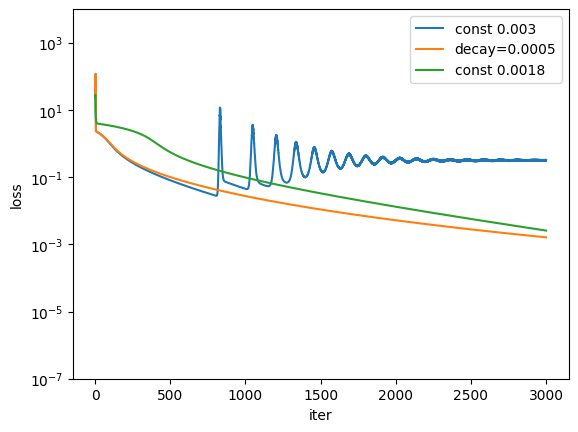

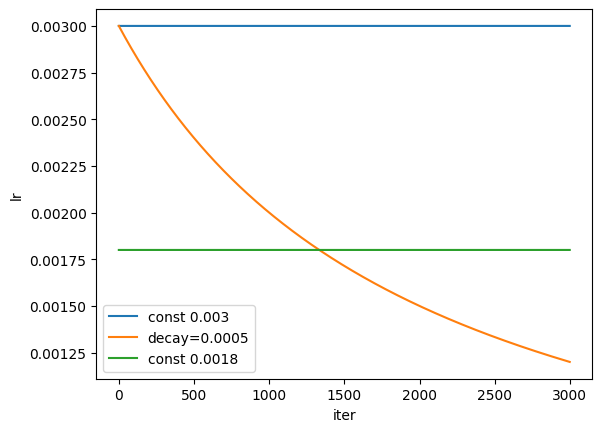

In [40]:
for label, hist in results.items():
    plt.plot(hist['loss'], label=label)
plt.yscale('log')
plt.ylim(1e-7, 1e4)
plt.xlabel('iter')
plt.ylabel('loss')
plt.legend()
plt.show()

for label, hist in results.items():
    plt.plot(hist['lr'], label=label)
plt.xlabel('iter')
plt.ylabel('lr')
plt.legend()
plt.show()

**Ваш ответ:**
*  шаг 0.003 застревает у дна, потому что шаг слишком велик для крутых стен
* расписание уменьшает шаг со временем, позволяя спуску успокоиться и продвинуться вдоль дна
* слишком большой decay быстро уменьшает шаг и спуск не успевает дойти, слишком маленький почти не помогает
* 0.0018 устойчив, но медленный, расписание с  шагом 0.003 например может дать лучший компромисс

**used help from ai to understand what to do with history thing*

### Задание 2.6. Градиентный спуск для линейной регрессии (1 балл)

Вернёмся к машинам и обучим линейную регрессию из 1.4 своим `GradientDescent`.

Добавим к признакам столбец из единиц — тогда свободный член (intercept) станет обычным весом $w_0$. Для матрицы признаков $X$ размера $n \times (d+1)$ и вектора весов $w$:
$$L(w) = \frac{1}{n}\,\|Xw - y\|^2 = \frac{1}{n}\sum_{i=1}^{n}(x_i^\top w - y_i)^2, \qquad \nabla L(w) = \frac{2}{n}\,X^\top (Xw - y).$$

1. **(0.25)** Реализуйте `mse_loss(w, X, y)` и `mse_grad(w, X, y)` по этим формулам — без циклов, через матричные операции NumPy (`@` — матричное умножение, `.T` — транспонирование).
2. **(0.25)** Запустите спуск из $w_0 = 0$ (`np.zeros(X_gd.shape[1])`) на `X_gd`, `y_gd` из ячейки ниже для шагов `[0.01, 0.1, 0.3, 0.5]` с `n_iterations=1000` и `tol=1`. Класс ожидает функции от одного аргумента `w`, поэтому передавайте `lambda w: mse_loss(w, X_gd, y_gd)` (и так же для градиента). Выведите для каждого шага число итераций и финальный loss, постройте кривые обучения (логарифмическая шкала; у расходящегося запуска в истории окажется `inf`, поэтому задайте пределы оси, например `plt.ylim(1e11, 1e13)`). При каком шаге спуск разошёлся?
3. **(0.25)** Сравните веса лучшего запуска с `lin_reg_scaled` из 1.4 (`intercept_` и `coef_`), сведите их в таблицу. Посчитайте $R^2$ своей модели на test: не забудьте добавить столбец единиц к `X_test_scaled`.
4. **(0.25)** Повторите спуск на **нестандартизированных** признаках: `X_train` из 1.1 со столбцом единиц, шаг `1e-10`, 1000 итераций (с шагом побольше спуск расходится, можете проверить). Сравните финальный loss с результатом на стандартизированных признаках. Почему без стандартизации спуск не справляется? Свяжите ответ с заданием 2.3.

In [41]:
# матрица признаков со столбцом единиц (для intercept) и таргет в виде массивов NumPy
X_gd = np.hstack([np.ones((X_train_scaled.shape[0], 1)), X_train_scaled])
y_gd = y_train.to_numpy()
print(X_gd.shape, y_gd.shape)

(5843, 7) (5843,)


In [42]:
def mse_loss(w, X, y):
    return np.mean((X @ w - y) ** 2)


def mse_grad(w, X, y):
    return (2 / X.shape[0]) * X.T @ (X @ w - y)  # ваш код здесь

In [43]:
# Проверка. Для квадратичной функции центральная разность точна при любом h, поэтому берём h=1
w_check = np.arange(X_gd.shape[1], dtype=float)
assert np.isclose(mse_loss(w_check, X_gd, y_gd), mean_squared_error(y_gd, X_gd @ w_check)), 'mse_loss считает неверно'
assert np.allclose(mse_grad(w_check, X_gd, y_gd),
                   numerical_grad(lambda w: mse_loss(w, X_gd, y_gd), w_check, h=1.0), rtol=1e-6), 'mse_grad считает неверно'
print('mse_loss и mse_grad посчитаны верно.')

mse_loss и mse_grad посчитаны верно.


lr=0.01: iters=1000, loss=116853792539.47372
lr=0.1: iters=318, loss=116851699648.09013
lr=0.3: iters=103, loss=116851699647.9494


/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:136: RuntimeWarning:

overflow encountered in reduce

/usr/local/lib/python3.13/dist-packages/matplotlib/scale.py:253: RuntimeWarning:

overflow encountered in power



lr=0.5: iters=727, loss=inf


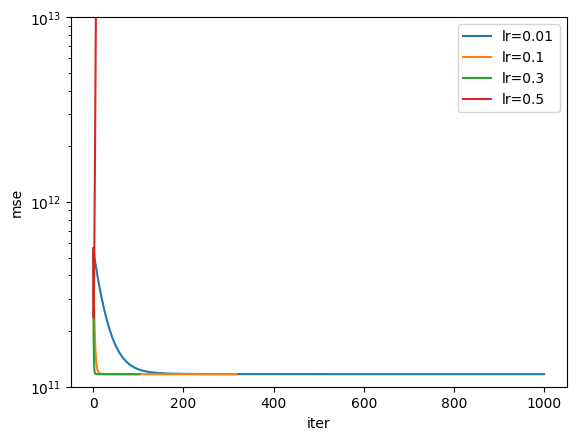

In [44]:
learning_rates_linreg = [0.01, 0.1, 0.3, 0.5]
results_linreg = {}

for lr in learning_rates_linreg:
    gd = GradientDescent(learning_rate=lr, n_iterations=1000, tol=1)
    gd.fit(lambda w: mse_loss(w, X_gd, y_gd), lambda w: mse_grad(w, X_gd, y_gd), np.zeros(X_gd.shape[1]))
    results_linreg[f'lr={lr}'] = gd.history
    print(f"lr={lr}: iters={len(gd.history['loss'])-1}, loss={gd.history['loss'][-1]}")


for label, hist in results_linreg.items():
    plt.plot(hist['loss'], label=label)
plt.yscale('log')
plt.ylim(1e11, 1e13)
plt.xlabel('iter')
plt.ylabel('mse')
plt.legend()
plt.show()

In [45]:
best_lr = 0.3
best_gd = GradientDescent(learning_rate=best_lr, n_iterations=1000, tol=1)
best_gd.fit(lambda w: mse_loss(w, X_gd, y_gd), lambda w: mse_grad(w, X_gd, y_gd), np.zeros(X_gd.shape[1]))

w_gd = best_gd.history['params'][-1]
w_sklearn = np.r_[lin_reg_scaled.intercept_, lin_reg_scaled.coef_]

compare = pd.DataFrame({'gd': w_gd, 'sk': w_sklearn}, index=['intercept'] + num_features)
display(compare)

X_test_gd = np.hstack([np.ones((X_test_scaled.shape[0], 1)), X_test_scaled])
y_pred_gd = X_test_gd @ w_gd
print("test R2 gd:", r2_score(y_test, y_pred_gd))

,gd,sk
intercept,522967.813110,522967.813110
year,152898.696383,152898.498205
km_driven,-43954.029712,-43953.853566
mileage,28791.922338,28791.816950
engine,61373.292038,61371.072884
max_power,322548.708506,322550.136077
seats,-23442.273501,-23441.054866


test R2 gd: 0.5939744451083098


In [46]:
X_gd_raw = np.hstack([np.ones((X_train.shape[0], 1)), X_train.to_numpy()])
y_gd_raw = y_train.to_numpy()

gd_raw = GradientDescent(learning_rate=1e-10, n_iterations=1000, tol=None)
gd_raw.fit(lambda w: mse_loss(w, X_gd, y_gd), lambda w: mse_grad(w, X_gd, y_gd), np.zeros(X_gd.shape[1]))
print("fin loss:", gd_raw.history['loss'][-1])

fin loss: 559992678895.0319


**Ваш ответ:**

без стандартизации признаки имеют слишком разный масштаб, из-за этого функция потерь вытянута, как квадратичная в 2.3, и градиентный спуск требует очень маленького шага. с стандартизацией шаг можно взять сильно больше

### Задание 2.7. Стохастический градиентный спуск (0.5 балла)

В стохастическом (mini-batch) градиентном спуске (SGD) градиент на каждом шаге считаем не по всей выборке, а по небольшому случайному подмножеству объектов — **батчу** (batch). Шаг становится намного дешевле, но градиент — шумным.

Нашему классу можно просто передать другую функцию градиента. Loss при этом по-прежнему считается по всей выборке, так кривые обучения удобно сравнивать.

1. **(0.2)** Допишите `mse_grad_batch(w, batch_size)`: выберите `batch_size` случайных номеров объектов без повторов (`rng.choice(n, size=batch_size, replace=False)`) и верните градиент MSE только по этим объектам (используйте `mse_grad`).
2. **(0.15)** Обучите SGD на `X_gd`, `y_gd` с `batch_size` 1, 32 и 256: шаг 0.01, 1000 итераций, `tol=None`. Постройте кривые обучения вместе с полным GD с тем же шагом.
3. **(0.15)** Ответьте: как размер батча влияет на вид кривой и на финальный loss? Почему для SGD не годится критерий остановки по норме градиента?

batch=1: fin loss=335809120100.582
batch=32: fin loss=117143543899.81067
batch=256: fin loss=116962161133.24014


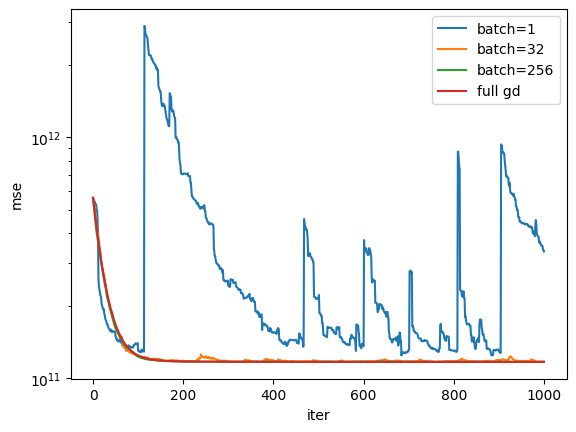

In [47]:
rng = np.random.default_rng(42)


def mse_grad_batch(w, batch_size):
    idx = rng.choice(X_gd.shape[0], size=batch_size, replace=False)
    return mse_grad(w, X_gd[idx], y_gd[idx])



results_sgd = {}
for bs in [1, 32, 256]:
    gd = GradientDescent(learning_rate=0.01, n_iterations=1000, tol=None)
    gd.fit(lambda w: mse_loss(w, X_gd, y_gd), lambda w: mse_grad_batch(w, bs), np.zeros(X_gd.shape[1]))
    results_sgd[f'batch={bs}'] = gd.history
    print(f"batch={bs}: fin loss={gd.history['loss'][-1]}")



gd_full = GradientDescent(learning_rate=0.01, n_iterations=1000, tol=None)
gd_full.fit(lambda w: mse_loss(w, X_gd, y_gd), lambda w: mse_grad(w, X_gd, y_gd), np.zeros(X_gd.shape[1]))
results_sgd['full gd'] = gd_full.history

for label, hist in results_sgd.items():
    plt.plot(hist['loss'], label=label)
plt.yscale('log')
plt.xlabel('iter')
plt.ylabel('mse')
plt.legend()
plt.show()

**Ваш ответ:**

 чем меньше батч - тем шумнее кривая финальный loss сильнее колеблется. больший батч даёт более ровные значения близкие к полному gd. критерий остановки  для sgd не подходит так как градиент по батчу - случайная величина и не стремится к нулю

## Чек-лист перед сдачей

- [ ] Перезапустил ядро и выполнил все ячейки сверху вниз — ошибок нет.
- [ ] Все выводы и графики сохранены в ноутбуке.
- [ ] Ответил текстом на все вопросы.
- [ ] Если пользовался LLM или чужим кодом, указал это.